# RSNA Knee - v5 A: build the image cache (CPU notebook)

Run this on **CPU** (Settings -> Accelerator -> None). It uses **no GPU hours**.

It reads every training study once, at the v5 settings, and saves:

- `cache.npy` - all studies as `(studies, 48 slices, 288, 288)` uint8, about 17.5 GB
- `uids.csv` - which study is in which row
- `prep.json` - the image settings (notebook C reads them, so test images are made the same way)

After it finishes: **Output -> New Dataset -> name it `knee-cache-v5`.**

Changes from v4 and why (from our research):

| | v4 | v5 | Why |
|---|---|---|---|
| Slices | 12 per plane | sagittal 20, coronal 16, axial 12 | more pictures per knee was the biggest gain for others (8 -> 16 pictures: 0.843 -> 0.911) |
| Size | 224 px (0.63 mm/pixel) | 288 px (0.49 mm/pixel) | small tears are 1-3 mm; strong models use 0.4-0.5 mm/pixel |
| Slice order | scanner slice direction | body axis (x, y or z) | the same order on every scanner |
| Crop | one pixel spacing | row and column spacing | correct for non-square pixels |
| Reading | one process | 4 processes | 4 CPU cores |

In [1]:
# Settings for the images. Notebook B and C read these from prep.json.
PREP = {
    "slices": {"Sagittal": 20, "Coronal": 16, "Axial": 12},
    "img_size": 288,
    "crop_mm": 140.0,
    "span": [0.06, 0.94],
    "version": "v5-body-axis-right-knees",
}
WORKERS = 4
LIMIT = None          # set e.g. 50 for a quick test

In [2]:
import os
import glob
import json
import time
import random

import cv2
import numpy as np
import pandas as pd
import pydicom

try:
    from pydicom.pixels import apply_voi_lut
except ImportError:
    from pydicom.pixel_data_handlers.util import apply_voi_lut

COMP = next(p for p in ["/kaggle/input/competitions/rsna-knee-abnormality-detection",
                        "/kaggle/input/rsna-knee-abnormality-detection"] if os.path.exists(p))

LABELS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]
PLANES = ["Sagittal", "Coronal", "Axial"]
print("data root:", COMP)

from multiprocessing import Pool
print("CPU cores:", os.cpu_count())

data root: /kaggle/input/competitions/rsna-knee-abnormality-detection
CPU cores: 4


In [3]:
def plane_blocks(prep):
    """Where each plane's slices sit inside one study's array."""
    blocks, start = {}, 0
    for plane in PLANES:
        n = prep["slices"][plane]
        blocks[plane] = (start, start + n)
        start += n
    return blocks


def pick_series(series_df):
    """One series per plane. Fluid-sensitive first (in this data it always equals fat-suppressed)."""
    ranked = series_df.sort_values(["Fluid_Sensitive", "Fat_Suppression"], ascending=False)
    rows = []
    for study, group in ranked.groupby("StudyInstanceUID"):
        row = {"StudyInstanceUID": str(study)}
        for plane in PLANES:
            same = group[group["Anatomical_Plane"] == plane]
            row[plane] = str(same.iloc[0]["SeriesInstanceUID"]) if len(same) else ""
        rows.append(row)
    return pd.DataFrame(rows)


def slice_key(header):
    """Position along the body axis the stack runs along (x for sagittal, y for coronal, z for axial).
    Using the body axis, not the scanner's slice direction, gives the same order on every scanner."""
    try:
        pos = np.array(header.ImagePositionPatient, dtype=float)
        orient = np.array(header.ImageOrientationPatient, dtype=float)
        normal = np.cross(orient[:3], orient[3:])
        return float(pos[int(np.argmax(np.abs(normal)))])
    except Exception:
        return float(getattr(header, "InstanceNumber", 0) or 0)


def sorted_paths(folder):
    ordered = []
    for path in glob.glob(os.path.join(folder, "*.dcm")):
        try:
            header = pydicom.dcmread(path, stop_before_pixels=True,
                                     specific_tags=["ImagePositionPatient", "ImageOrientationPatient", "InstanceNumber"])
            ordered.append((slice_key(header), path))
        except Exception:
            continue
    ordered.sort(key=lambda item: item[0])
    return [path for _, path in ordered]


def read_image(path):
    """One slice as floats, plus mm per pixel along rows and columns."""
    try:
        data = pydicom.dcmread(path)
        try:
            image = apply_voi_lut(data.pixel_array, data).astype(np.float32)
        except Exception:
            image = np.asarray(data.pixel_array, dtype=np.float32)
        image = np.nan_to_num(np.squeeze(image), nan=0.0, posinf=0.0, neginf=0.0)
        if image.ndim != 2:
            return None, None
        if getattr(data, "PhotometricInterpretation", "") == "MONOCHROME1":
            image = image.max() - image
        spacing = getattr(data, "PixelSpacing", None)
        mm = (float(spacing[0]), float(spacing[1])) if spacing is not None and len(spacing) >= 2 else None
        return image, mm
    except Exception:
        return None, None


def crop_to_mm(image, mm, crop_mm):
    """Keep the same real area of knee, whatever the scanner's pixel size."""
    if not mm or mm[0] <= 0 or mm[1] <= 0:
        return image
    half_y, half_x = int(round(crop_mm / mm[0] / 2)), int(round(crop_mm / mm[1] / 2))
    mid_y, mid_x = image.shape[0] // 2, image.shape[1] // 2
    cropped = image[max(mid_y - half_y, 0):mid_y + half_y, max(mid_x - half_x, 0):mid_x + half_x]
    return cropped if cropped.size else image


def load_series(folder, n, prep):
    size = prep["img_size"]
    empty = np.zeros((n, size, size), dtype=np.uint8)
    paths = sorted_paths(folder)
    if not paths:
        return empty

    start = int(prep["span"][0] * len(paths))
    stop = max(int(prep["span"][1] * len(paths)), start + 1)
    picked = np.linspace(start, stop - 1, n).round().astype(int)

    slices, last_good = [], None
    for i in picked:
        image, mm = read_image(paths[i])
        if image is None:
            slices.append(last_good if last_good is not None else np.zeros((size, size), np.float32))
            continue
        image = cv2.resize(crop_to_mm(image, mm, prep["crop_mm"]), (size, size), interpolation=cv2.INTER_AREA)
        slices.append(image)
        last_good = image

    stack = np.stack(slices).astype(np.float32)
    low, high = np.percentile(stack, [1, 99])         # one window for the whole series
    stack = (np.clip(stack, low, high) - low) / max(high - low, 1e-6)
    return (stack * 255).astype(np.uint8)


def knee_side(study_uid, row, root):
    """'L', 'R' or None. Laterality tag first, else where the image centre sits (right knee at x < 0)."""
    tags, centres = [], []
    for plane in PLANES:
        series_uid = row.get(plane, "")
        if not isinstance(series_uid, str) or not series_uid:
            continue
        files = glob.glob(os.path.join(root, study_uid, series_uid, "*.dcm"))
        if not files:
            continue
        try:
            h = pydicom.dcmread(files[0], stop_before_pixels=True)
        except Exception:
            continue
        tag = str(getattr(h, "Laterality", "") or "").strip().upper()
        if tag[:1] in ("L", "R"):
            tags.append(tag[0])
        try:
            pos = np.array(h.ImagePositionPatient, dtype=float)
            orient = np.array(h.ImageOrientationPatient, dtype=float)
            spacing = np.array(h.PixelSpacing, dtype=float)
            centre = (pos + orient[:3] * spacing[1] * float(h.Columns) / 2
                          + orient[3:] * spacing[0] * float(h.Rows) / 2)
            centres.append(centre[0])
        except Exception:
            pass
    if tags:
        return tags[0]
    if centres and abs(float(np.median(centres))) >= 20:
        return "R" if float(np.median(centres)) < 0 else "L"
    return None


def load_study(study_uid, row, root, prep):
    """One study as (all slices, size, size) uint8: sagittal block, coronal block, axial block.
    Left knees are mirrored so every knee looks like a right knee. Missing planes stay black."""
    blocks = plane_blocks(prep)
    total = blocks[PLANES[-1]][1]
    volume = np.zeros((total, prep["img_size"], prep["img_size"]), dtype=np.uint8)

    for plane in PLANES:
        series_uid = row.get(plane, "")
        if isinstance(series_uid, str) and series_uid:
            a, b = blocks[plane]
            try:
                volume[a:b] = load_series(os.path.join(root, study_uid, series_uid), b - a, prep)
            except Exception:
                pass

    try:
        if knee_side(study_uid, row, root) == "L":
            a, b = blocks["Sagittal"]
            volume[a:b] = volume[a:b][::-1]                  # sagittal: read the stack backwards
            for plane in ("Coronal", "Axial"):
                a, b = blocks[plane]
                volume[a:b] = volume[a:b, :, ::-1]           # coronal / axial: flip left-right
    except Exception:
        pass
    return volume

In [4]:
train = pd.read_csv(f"{COMP}/train.csv")
series = pd.read_csv(f"{COMP}/train_series.csv")
chosen = pick_series(series).set_index("StudyInstanceUID")

uids = train["StudyInstanceUID"].astype(str).tolist()[:LIMIT]
total = sum(PREP["slices"].values())
shape = (len(uids), total, PREP["img_size"], PREP["img_size"])
need_gb = np.prod(shape) / 1e9
print("studies:", len(uids), " shape:", shape, f" size: {need_gb:.1f} GB")
assert need_gb < 19.5, "too big for /kaggle/working (20 GB): lower img_size or slices"

studies: 4407  shape: (4407, 48, 288, 288)  size: 17.5 GB


In [5]:
ROOT = f"{COMP}/train_series"


def work(i):
    uid = uids[i]
    row = chosen.loc[uid].to_dict() if uid in chosen.index else {}
    try:
        return i, load_study(uid, row, ROOT, PREP)
    except Exception:
        return i, np.zeros(shape[1:], dtype=np.uint8)


os.makedirs("/kaggle/working", exist_ok=True)
cache = np.lib.format.open_memmap("/kaggle/working/cache.npy", mode="w+", dtype=np.uint8, shape=shape)

start = time.time()
with Pool(WORKERS) as pool:
    for done, (i, volume) in enumerate(pool.imap_unordered(work, range(len(uids)), chunksize=4), 1):
        cache[i] = volume
        if done % 250 == 0 or done == len(uids):
            mins = (time.time() - start) / 60
            print(f"  {done}/{len(uids)}   {mins:.1f} min   about {mins / done * (len(uids) - done):.0f} min left")
cache.flush()

pd.DataFrame({"StudyInstanceUID": uids}).to_csv("/kaggle/working/uids.csv", index=False)
json.dump(PREP, open("/kaggle/working/prep.json", "w"), indent=1)
print(f"done in {(time.time() - start) / 60:.1f} min")

  250/4407   1.7 min   about 28 min left
  500/4407   3.2 min   about 25 min left
  750/4407   4.9 min   about 24 min left
  1000/4407   6.6 min   about 23 min left
  1250/4407   8.4 min   about 21 min left
  1500/4407   10.1 min   about 20 min left
  1750/4407   11.7 min   about 18 min left
  2000/4407   13.5 min   about 16 min left
  2250/4407   15.4 min   about 15 min left
  2500/4407   17.0 min   about 13 min left
  2750/4407   18.8 min   about 11 min left
  3000/4407   20.7 min   about 10 min left
  3250/4407   22.6 min   about 8 min left
  3500/4407   24.4 min   about 6 min left
  3750/4407   26.2 min   about 5 min left
  4000/4407   28.0 min   about 3 min left
  4250/4407   29.7 min   about 1 min left
  4407/4407   31.0 min   about 0 min left
done in 31.0 min


### Look at one study

Each row is one plane. You should see a knee in every row (black rows = that plane is missing).

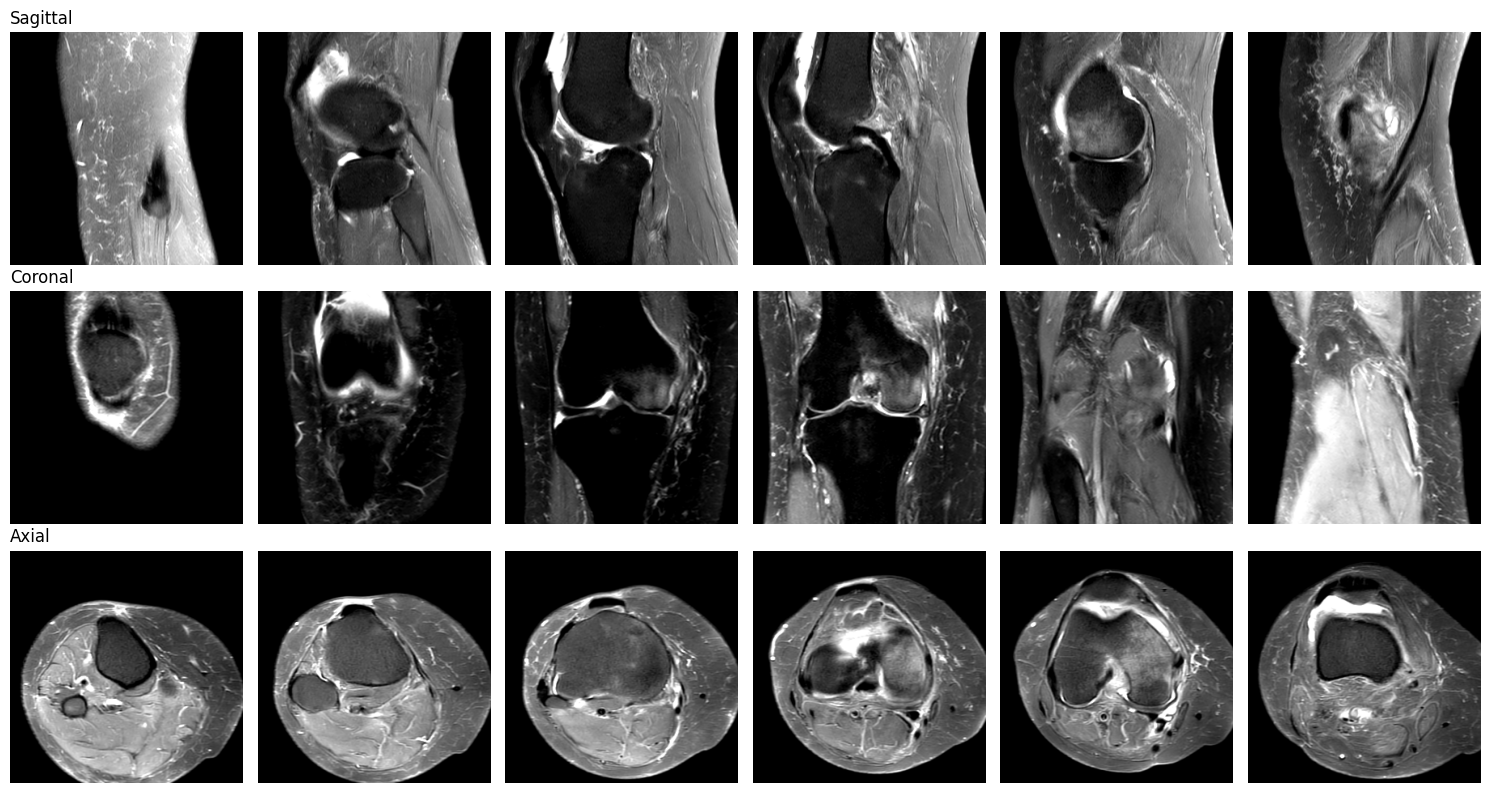

Sagittal  missing in 0.1% of studies
Coronal   missing in 0.3% of studies
Axial     missing in 0.3% of studies


In [6]:
import matplotlib.pyplot as plt

volume = cache[0]
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for p, plane in enumerate(PLANES):
    a, b = plane_blocks(PREP)[plane]
    for k, s in enumerate(np.linspace(a, b - 1, 6).astype(int)):
        axes[p, k].imshow(volume[s], cmap="gray")
        axes[p, k].axis("off")
    axes[p, 0].set_title(plane, loc="left")
plt.tight_layout()
plt.show()

empty = (cache.reshape(len(uids), total, -1).max(axis=2) == 0)
for plane in PLANES:
    a, b = plane_blocks(PREP)[plane]
    print(f"{plane:9s} missing in {empty[:, a:b].all(axis=1).mean():.1%} of studies")